In [24]:
import pandas as pd
import numpy as np
import torch
from pathlib import Path
import torch.nn as nn
import math
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

MAX_LENGTH = 64
PAD_ID = 0
UNK_ID = 1

In [2]:
val_df = pd.read_csv("../data/val_split.csv")

print("Validation Samples:", len(val_df))
print("Number of Classes:", val_df["label"].nunique())
print("\nClass Distribution:")
print(val_df["label"].value_counts().sort_index())

assert len(val_df) == 800
assert val_df["label"].value_counts().eq(200).all()

Validation Samples: 800
Number of Classes: 4

Class Distribution:
label
0    200
1    200
2    200
3    200
Name: count, dtype: int64


In [3]:
files = {
    "Transformer Weights": "../models/newsroute_transformer.pt",
    "Vocabulary": "../models/vocab.json",
}

for name, path in files.items():
    print(f"{name}: {'EXISTS' if Path(path).exists() else 'MISSING'}")

Transformer Weights: EXISTS
Vocabulary: MISSING


In [4]:
models_dir = Path("../models")

print("Models directory:")

for file in models_dir.iterdir():
    print(file.name)

Models directory:
newsroute_transformer.pt


In [ ]:
import json
from pathlib import Path

train_df = pd.read_csv("../data/train_split.csv")

PAD_ID = 0
UNK_ID = 1


def tokenize(text):
    return text.lower().split()


def build_vocab(texts):
    vocab = {
        "[PAD]": PAD_ID,
        "[UNK]": UNK_ID
    }

    for text in texts:
        for token in tokenize(text):
            if token not in vocab:
                vocab[token] = len(vocab)

    return vocab


vocab = build_vocab(train_df["text"])

print("Training Samples:", len(train_df))
print("Vocabulary Size:", len(vocab))
print("First Tokens:", list(vocab.items())[:5])


assert len(train_df) == 3200
assert len(vocab) == 7787


vocab_path = Path("../models/vocab.json")

with open(vocab_path, "w", encoding="utf-8") as f:
    json.dump(vocab, f, ensure_ascii=False, indent=2)

print("Vocabulary Saved:", vocab_path.exists())

In [ ]:

tfidf_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        lowercase=True
    )),
    ("classifier", LogisticRegression(max_iter=1000))
])


tfidf_model.fit(train_df["text"], train_df["label"])


tfidf_preds = tfidf_model.predict(val_df["text"])

tfidf_accuracy = accuracy_score(
    val_df["label"], tfidf_preds
)

tfidf_macro_f1 = f1_score(
    val_df["label"],
    tfidf_preds,
    average="macro"
)

print("TF-IDF Validation Samples:", len(tfidf_preds))
print(f"Accuracy: {tfidf_accuracy:.4f}")
print(f"Macro-F1: {tfidf_macro_f1:.4f}")

TF-IDF Validation Samples: 800
Accuracy: 0.8712
Macro-F1: 0.8711


In [15]:
def positional_encoding(seq_len, d_model):

    positions = torch.arange(seq_len).unsqueeze(1)

    div_term = torch.exp(
        torch.arange(0, d_model, 2).float()
        * (-math.log(10000.0) / d_model)
    )
    angles = positions * div_term

    PE = torch.zeros(seq_len , d_model)
    PE[:, 0::2] = torch.sin(angles)
    PE[:, 1::2] = torch.cos(angles)

    return PE

In [16]:
class NewsRouteTransformer(nn.Module):

    def __init__(
        self,
        vocab_size,
        d_model=64,
        num_heads=4,
        num_layers=1,
        num_classes=4
    ):
        super().__init__()

        # 1. Embedding
        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=PAD_ID
        )

        # 2. Positional Encoding
        self.register_buffer(
            "pe",
            positional_encoding(MAX_LENGTH, d_model)
        )

        # 3. Transformer Encoder Layer
        self.encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True
        )

        # 4. Transformer Encoder
        self.encoder = nn.TransformerEncoder(
            encoder_layer=self.encoder_layer,
            num_layers=num_layers
        )

        # 5. Classification Head
        self.classifier = nn.Linear(
            in_features=d_model,
            out_features=num_classes
        )

    def forward(self, input_ids):

        # 1. Padding Mask
        padding_mask = input_ids == PAD_ID

        # 2. Embedding
        x = self.embedding(input_ids)

        # 3. Positional Encoding
        x = x + self.pe[:input_ids.size(1)].unsqueeze(0)

        # 4. Transformer Encoder
        x = self.encoder(
            src=x,
            src_key_padding_mask=padding_mask
        )

        # 5. Masked Mean Pooling
        valid_mask = input_ids != PAD_ID

        mask = valid_mask.unsqueeze(-1).float()

        mask_x = x * mask

        token_sum = mask_x.sum(dim=1)

        token_count = mask.sum(dim=1).clamp(min=1)

        pooled = token_sum / token_count

        # 6. Classification Head
        logits = self.classifier(pooled)

        return logits

In [17]:
import json

with open("../models/vocab.json", "r", encoding="utf-8") as f:
    vocab = json.load(f)

print("Vocabulary Size:", len(vocab))
print("First Tokens:", list(vocab.items())[:5])

assert len(vocab) == 7787
assert vocab["[PAD]"] == 0
assert vocab["[UNK]"] == 1

transformer_model = NewsRouteTransformer(
    vocab_size=len(vocab),
    d_model=64,
    num_heads=4,
    num_layers=1,
    num_classes=4
)

transformer_model.load_state_dict(
    torch.load(
        "../models/newsroute_transformer.pt",
        map_location="cpu",
        weights_only=True
    )
)

transformer_model.eval()

print("Transformer başarıyla yüklendi.")
print("Model Device:", next(transformer_model.parameters()).device)


Vocabulary Size: 7787
First Tokens: [('[PAD]', 0), ('[UNK]', 1), ('new', 2), ('fcc', 3), ('rule', 4)]
Transformer başarıyla yüklendi.
Model Device: cpu


In [18]:
def encode_text(text, vocab, max_length):
    tokens = tokenize(text)

    token_ids = [
        vocab.get(token, UNK_ID)
        for token in tokens
    ]

    token_ids = token_ids[:max_length]

    padding_length = max_length - len(token_ids)

    token_ids = token_ids + [PAD_ID] * padding_length

    return token_ids



val_encoded = [
    encode_text(text, vocab, MAX_LENGTH)
    for text in val_df["text"]
]


X_val_transformer = torch.tensor(
    val_encoded,
    dtype=torch.long
)

y_val_transformer = torch.tensor(
    val_df["label"].to_numpy(),
    dtype=torch.long
)

print("Transformer Input Shape:", X_val_transformer.shape)
print("Validation Labels Shape:", y_val_transformer.shape)

Transformer Input Shape: torch.Size([800, 64])
Validation Labels Shape: torch.Size([800])


In [19]:
transformer_model.eval()

with torch.no_grad():
    transformer_logits = transformer_model(X_val_transformer)
    transformer_preds = torch.argmax(transformer_logits, dim=1).numpy()

print("Transformer Predictions:", len(transformer_preds))
print("TF-IDF Predictions:", len(tfidf_preds))

assert len(transformer_preds) == len(tfidf_preds) == 800
assert np.array_equal(y_val_transformer.numpy(), val_df["label"].to_numpy())

/home/pasali/anaconda3/envs/myenv/lib/python3.14/site-packages/torch/nn/modules/transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:177.)
  output = torch._nested_tensor_from_mask(


Transformer Predictions: 800
TF-IDF Predictions: 800


In [20]:
y_true = val_df["label"].to_numpy()

tfidf_predictions = tfidf_preds

transformer_predictions = transformer_preds

print("y_true:", y_true.shape)
print("TF-IDF:", tfidf_predictions.shape)
print("Transformer:", transformer_predictions.shape)

y_true: (800,)
TF-IDF: (800,)
Transformer: (800,)


In [21]:
assert len(y_true) == len(tfidf_predictions) == len(transformer_predictions) == 800

print("İlk haber:", val_df.iloc[0]["text"][:150])
print("Gerçek etiket:", y_true[0])
print("TF-IDF tahmini:", tfidf_predictions[0])
print("Transformer tahmini:", transformer_predictions[0])

first_encoded = encode_text(
    val_df.iloc[0]["text"],
    vocab,
    MAX_LENGTH
)

assert X_val_transformer[0].tolist() == first_encoded

print("\nİlk haberin Transformer girişi doğrulandı.")

İlk haber: one cap india exclusive satellite service successfully placed orbit monday
Gerçek etiket: 0
TF-IDF tahmini: 3
Transformer tahmini: 3

İlk haberin Transformer girişi doğrulandı.


In [23]:
class_names = ["World", "Sports", "Business", "Sci/Tech"]


def evaluate_model(y_true, y_pred):

    recalls = recall_score(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        average=None,
        zero_division=0
    )

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro-F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "World Recall": recalls[0],
        "Sports Recall": recalls[1],
        "Business Recall": recalls[2],
        "Sci/Tech Recall": recalls[3]
    }



tfidf_metrics = evaluate_model(y_true, tfidf_predictions)


transformer_metrics = evaluate_model(y_true, transformer_predictions)


comparison_df = pd.DataFrame({
    "TF-IDF": tfidf_metrics,
    "Transformer": transformer_metrics
})

print(comparison_df.round(4))

                 TF-IDF  Transformer
Accuracy         0.8712       0.7138
Macro Precision  0.8719       0.7143
Macro Recall     0.8712       0.7138
Macro-F1         0.8711       0.7108
World Recall     0.8600       0.7700
Sports Recall    0.9650       0.7950
Business Recall  0.8050       0.5550
Sci/Tech Recall  0.8550       0.7350


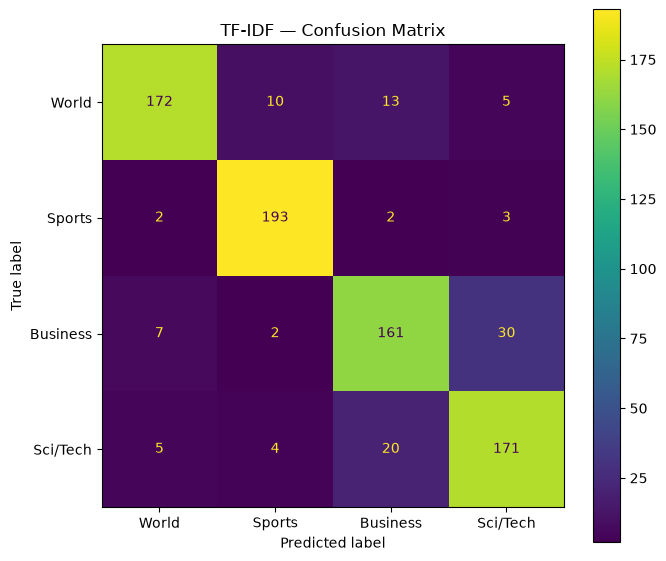

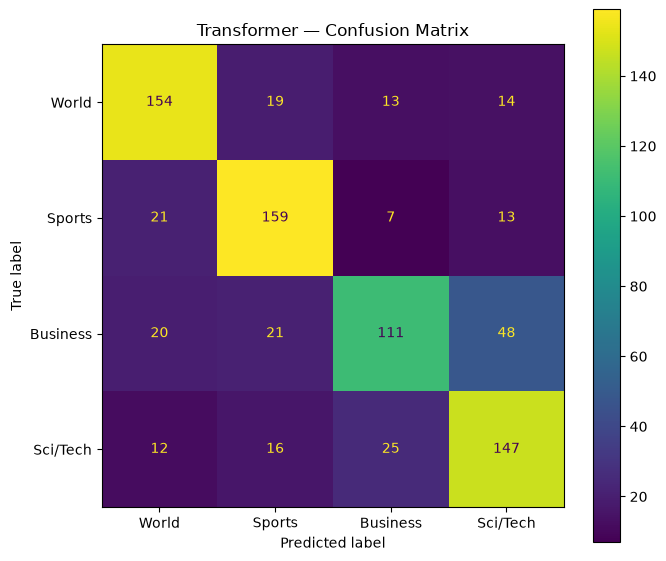

In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay

figures_dir = Path("../figures")
figures_dir.mkdir(parents=True, exist_ok=True)


def plot_confusion_matrix(y_true, y_pred, model_name, filename):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3]
    )

    fig, ax = plt.subplots(figsize=(7, 6))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        values_format="d"
    )

    ax.set_title(f"{model_name} — Confusion Matrix")

    plt.tight_layout()

    plt.savefig(
        figures_dir / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)



plot_confusion_matrix(
    y_true,
    tfidf_predictions,
    "TF-IDF",
    "tfidf_confusion_matrix.png"
)

plot_confusion_matrix(
    y_true,
    transformer_predictions,
    "Transformer",
    "transformer_confusion_matrix.png"
)

In [26]:
wrong_mask = transformer_predictions != y_true

wrong_indices = np.where(wrong_mask)[0]

print("Toplam yanlış tahmin:", len(wrong_indices))


rng = np.random.default_rng(42)

sample_counts = {
    0: 2,  # World
    1: 2,  # Sports
    2: 3,  # Business
    3: 3   # Sci/Tech
}

selected_indices = []

for label, count in sample_counts.items():

    candidates = wrong_indices[y_true[wrong_indices] == label]

    selected = rng.choice(
        candidates,
        size=count,
        replace=False
    )

    selected_indices.extend(selected.tolist())

selected_indices = sorted(selected_indices)

wrong_df = pd.DataFrame({
    "row_id": selected_indices,
    "text": val_df.iloc[selected_indices]["text"].to_numpy(),
    "actual_label": y_true[selected_indices],
    "tfidf_prediction": tfidf_predictions[selected_indices],
    "transformer_prediction": transformer_predictions[selected_indices]
})

print("Seçilen haber sayısı:", len(wrong_df))

Toplam yanlış tahmin: 229
Seçilen haber sayısı: 10


In [27]:
from pathlib import Path

class_names = ["World", "Sports", "Business", "Sci/Tech"]

preview_df = wrong_df.copy()

for col in ["actual_label", "tfidf_prediction", "transformer_prediction"]:
    preview_df[col] = preview_df[col].map(
        lambda x: class_names[x]
    )

preview_df["text"] = preview_df["text"].apply(
    lambda text: text[:180] + ("..." if len(text) > 180 else "")
)

display(preview_df)


reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

wrong_df.to_csv(
    reports_dir / "ten_wrong_predictions.csv",
    index=False
)

print("CSV kaydedildi: reports/ten_wrong_predictions.csv")

,row_id,text,actual_label,tfidf_prediction,transformer_prediction
0,67,eu monti reveals support santander abbey bid m...,Business,Business,World
1,124,least death blamed hurricane ivan update sat p...,World,World,Sports
2,132,th circuit order healthsouth exec birmingham a...,Business,Business,World
3,227,panis take step back olivier panis announced r...,Sports,Sports,Sci/Tech
4,554,oil charge nigeria threat ltpgtltpgtltpgt andr...,Business,Business,Sports
5,626,cbs say cant vouch bush document cbs admitted ...,World,World,Sci/Tech
6,628,hp unix base offered opteron come sun,Sci/Tech,Sci/Tech,Sports
7,648,new sony walkman challenge ipod mini sony new ...,Sci/Tech,Sci/Tech,Sports
8,757,nasa aim mach nasa try morning set speed recor...,Sci/Tech,Sci/Tech,Sports
9,771,skater baffled fall world champion skater said...,Sports,Sports,Business


CSV kaydedildi: reports/ten_wrong_predictions.csv


In [30]:
comparison_results = pd.DataFrame([
    {
        "model": "TFIDF_LogisticRegression",
        "validation_samples": len(y_true),
        "accuracy": tfidf_metrics["Accuracy"],
        "macro_precision": tfidf_metrics["Macro Precision"],
        "macro_recall": tfidf_metrics["Macro Recall"],
        "macro_f1": tfidf_metrics["Macro-F1"]
    },
    {
        "model": "NewsRouteTransformer",
        "validation_samples": len(y_true),
        "accuracy": transformer_metrics["Accuracy"],
        "macro_precision": transformer_metrics["Macro Precision"],
        "macro_recall": transformer_metrics["Macro Recall"],
        "macro_f1": transformer_metrics["Macro-F1"]
    }
])


assert len(comparison_results) == 2
assert comparison_results["validation_samples"].eq(800).all()


reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

comparison_results.to_csv(
    reports_dir / "friday_model_comparison.csv",
    index=False
)

display(comparison_results.round(4))

print("CSV başarıyla kaydedildi.")

,model,validation_samples,accuracy,macro_precision,macro_recall,macro_f1
0,TFIDF_LogisticRegression,800,0.8712,0.8719,0.8712,0.8711
1,NewsRouteTransformer,800,0.7138,0.7143,0.7138,0.7108


CSV başarıyla kaydedildi.


In [32]:
# TEST 1 — Validation Alignment

assert len(y_true) == len(tfidf_predictions) == len(transformer_predictions) == 800


assert np.array_equal(y_true, val_df["label"].to_numpy())


assert np.array_equal(
    tfidf_predictions,
    tfidf_model.predict(val_df["text"])
)


expected_encoded = [
    encode_text(text, vocab, MAX_LENGTH)
    for text in val_df["text"]
]

assert np.array_equal(
    X_val_transformer.numpy(),
    np.array(expected_encoded)
)

print("Test 1 — Validation Alignment: PASSED")


# TEST 2 — Confusion Matrix

cm_tfidf = confusion_matrix(
    y_true, tfidf_predictions, labels=[0, 1, 2, 3]
)

cm_transformer = confusion_matrix(
    y_true, transformer_predictions, labels=[0, 1, 2, 3]
)

assert cm_tfidf.shape == (4, 4)
assert cm_transformer.shape == (4, 4)

assert cm_tfidf.sum() == 800
assert cm_transformer.sum() == 800

print("Test 2 — Confusion Matrix: PASSED")


# TEST 3 — Wrong Predictions

assert len(wrong_df) == 10
assert wrong_df["row_id"].nunique() == 10

row_ids = wrong_df["row_id"].to_numpy()

assert np.all((row_ids >= 0) & (row_ids < 800))

assert np.array_equal(
    wrong_df["actual_label"].to_numpy(),
    y_true[row_ids]
)

assert np.array_equal(
    wrong_df["transformer_prediction"].to_numpy(),
    transformer_predictions[row_ids]
)

assert (
    wrong_df["actual_label"] != wrong_df["transformer_prediction"]
).all()

print("Test 3 — Wrong Predictions: PASSED")

Test 1 — Validation Alignment: PASSED
Test 2 — Confusion Matrix: PASSED
Test 3 — Wrong Predictions: PASSED
